In [1]:
import numpy as np
import matplotlib.pyplot as plt
from DistanceProject import DistanceAnalysis, create_new_result_dir
from DistancePlots import *
import os
import pickle
import seaborn as sns

%load_ext autoreload
%autoreload 2

data_dir = r'D:/data-distance-coding-project/processed-data'

In [71]:
imaging_filename = r'240724_SAM019_1'

imaging_dir = os.path.join(data_dir, imaging_filename)
result_dir = data_dir + '/' + str(imaging_filename) + '/results'
object_filename = imaging_dir + '/' + imaging_filename + '_distance.pkl'

if os.path.exists(object_filename):
    with open(object_filename, 'rb') as f:
        D = pickle.load(f)
        print('Loaded DistanceAnalysis object')
else:
    D = DistanceAnalysis(imaging_dir, angle_range = np.linspace(-40, 60, 100), activity_mode='dFF', run_session=True, n_iterations=100)
    
D.extract_characteristics_all()

Loaded DistanceAnalysis object
 Cell 377

(['un-modulated',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'un-reliable',
  'un-reliable',
  'un-modulated',
  'un-modulated',
  'un-reliable',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'un-modulated',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'binocular',
  'un-reliable',
  'un-modulated',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'un-reliable',
  'un-modulated',
  'binocular',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-reliable',
  'un-modulated',
  'un-modulated',
  'un-reliable',
  'un-rel

# See what is the receptive field distribution

Text(0.5, 32.72222222222221, 'Preferred Angle')

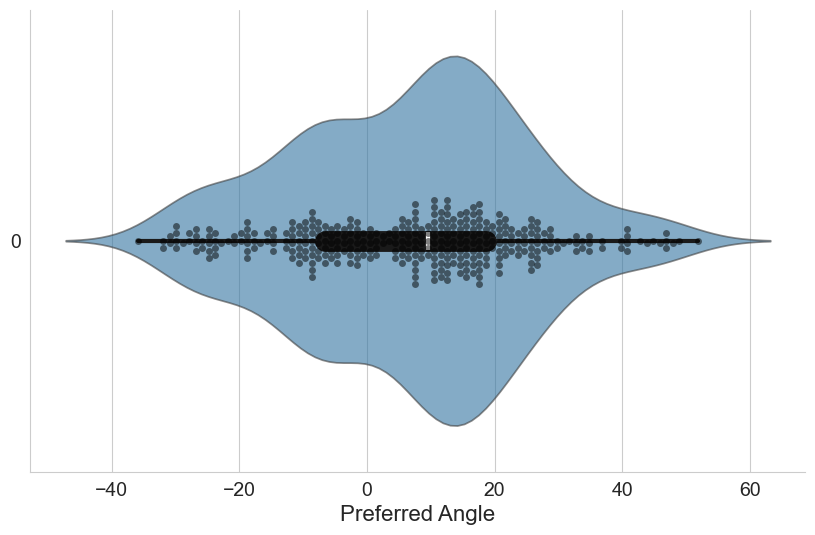

In [23]:
preferred_angle = []

# get cells that are not un-reliable
reliable = np.array(D.stats['type']) != 'un-reliable'
preferred_angle.append(np.array(D.stats['preferred_angle'])[reliable])
    # plot violin plot of all the sessions with their preferred angle
plt.figure(figsize=(10, 6))
sns.swarmplot(data=preferred_angle, orient='h', color='k', alpha=0.5)
sns.violinplot(data=preferred_angle, orient='h', alpha=0.6, inner_kws=dict(box_width=15, whis_width=3, color=".1"))

# remove splines
sns.despine()
plt.xlabel('Preferred Angle')

0
1


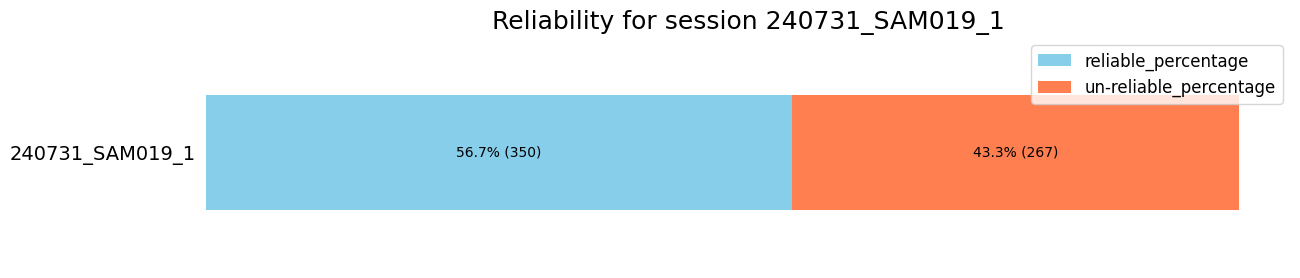

In [240]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Compute counts and percentages for two categories: reliable and un-reliable
categories = ['reliable', 'un-reliable']

# Count the number of cells in each category
type = D.stats['type']
counts = [sum(np.array(type) != 'un-reliable'), type.count('un-reliable')]

# Calculate percentages
total_counts = sum(counts)
percentages = [count / total_counts * 100 for count in counts]

# Prepare data for plotting
# add counts too
data = {'Session': [imaging_filename]}
for i, category in enumerate(categories):
    data[f'{category}_percentage'] = [percentages[i]]
    # data[f'{category}_count'] = [counts[i]]
    
    

df = pd.DataFrame(data)

# Plot a Stacked Bar Chart using matplotlib
fig, ax = plt.subplots(figsize=(14, 3))  # Adjust the figsize to make the figure wider
df.set_index('Session').plot(
    kind='barh',
    stacked=True,
    title=f'Reliability for session {imaging_filename}',
    mark_right=True,
    ax=ax,
    color=['skyblue', 'coral']
)

# Calculate total counts and relative percentages
df_total = df.iloc[:, 1:].sum(axis=1)
df_rel = df.iloc[:, 1:].div(df_total, axis=0) * 100

for j, n in enumerate(df_rel.columns):
    print(j)
    for i, (cs, ab, pc) in enumerate(zip(df.iloc[:, 1:].cumsum(axis=1)[n], df[n], df_rel[n])):
        plt.text(cs - ab / 2, i, f'{np.round(pc, 1)}% ({int(counts[j])})', va='center', ha='center', color='k')

plt.xlabel('Counts')

# Remove border of the plot
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# Add ticks
ax.tick_params(left=False, bottom=True)

# Remove y label
plt.ylabel('')
plt.xlabel('')

# Remove y ticks and labels
plt.xticks([])

plt.show()

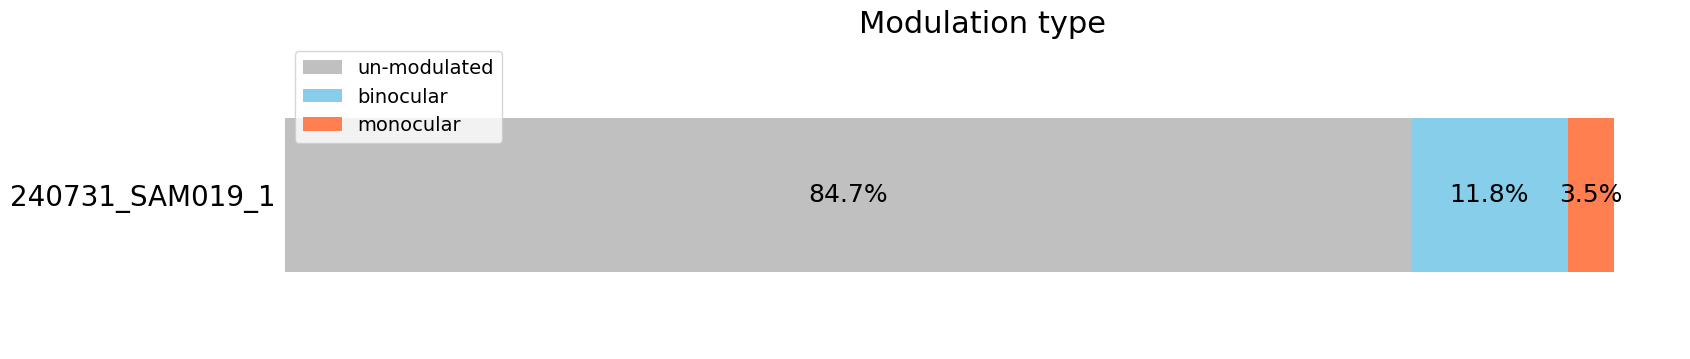

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Compute counts and percentages
categories = ['un-modulated', 'binocular', 'monocular']

cat_count = []

type = D.stats['type']
counts = [type.count(cat) for cat in categories]
cat_count.append(counts)

cat_pcgt = []
for count in cat_count:
    total_counts = sum(count)
    percentages = [i / total_counts * 100 for i in count]
    cat_pcgt.append(percentages)

# Select a specific session (e.g., the first session)
session_index = 0
selected_session = imaging_filename
selected_counts = cat_pcgt[session_index]

# Prepare data for plotting
data = {'Session': [selected_session]}
for i, category in enumerate(categories):
    data[category] = [selected_counts[i]]

df = pd.DataFrame(data)

# Plot a Stacked Bar Chart using matplotlib
fig, ax = plt.subplots(figsize=(18, 4))  # Adjust the figsize to make the figure wider
df.set_index('Session').plot(
    kind='barh',
    stacked=True,
    title=f'Modulation type for session {selected_session}',
    mark_right=True,
    ax=ax,
    color=['silver', 'skyblue', 'coral', 'plum']
)

# Calculate total counts and relative percentages
df_total = df.iloc[:, 1:].sum(axis=1)
df_rel = df.iloc[:, 1:].div(df_total, axis=0) * 100

# Add percentage labels to the bars
for n in df_rel.columns:
    for i, (cs, ab, pc) in enumerate(zip(df.iloc[:, 1:].cumsum(axis=1)[n], df[n], df_rel[n])):
        plt.text(cs - ab / 2, i, f'{np.round(pc, 1)}%', va='center', ha='center', color='k', fontsize=18)

# Remove border of the plot
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# set legend to size 14
plt.legend(fontsize=14)

# Add ticks
ax.tick_params(left=False, bottom=True)

# se title to size 22
plt.title('Modulation type', fontsize=22)

# Remove y label
plt.ylabel('')

# remove xticks labels
plt.xticks([])

# set text of the left to be bigger
plt.yticks(fontsize=20)

plt.show()

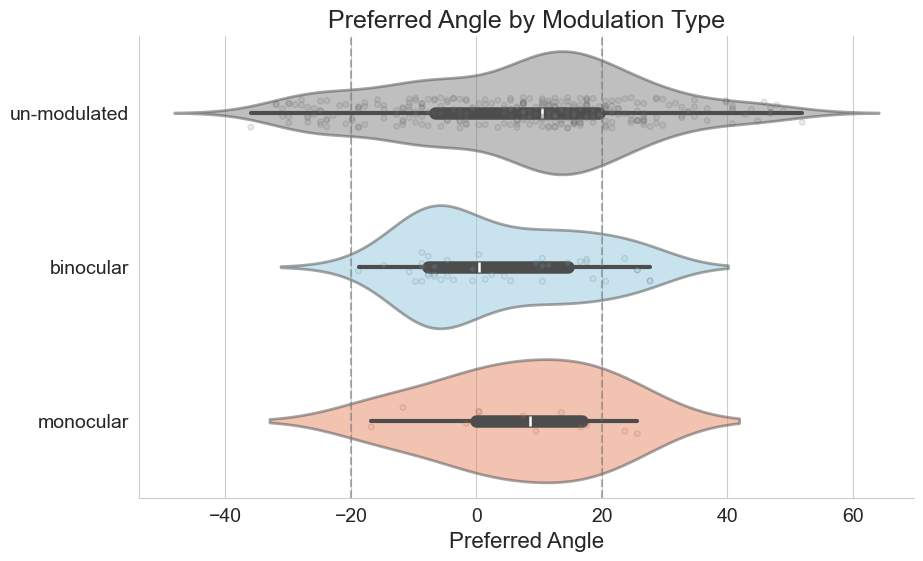

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Extract preferred_angle for each modulation type
unmodulated_RF = []
binocular_RF = []
monocular_RF = []

for cell in range(D.dFF.shape[0]):
    type = D.stats['type'][cell]
    preferred_angle = D.stats['preferred_angle'][cell]

    if type == 'un-reliable':
        continue

    if type == 'un-modulated':
        unmodulated_RF.append(preferred_angle)
    elif type == 'binocular':
        binocular_RF.append(preferred_angle)
    elif type == 'monocular':
        monocular_RF.append(preferred_angle)

# Prepare data for plotting
data = [unmodulated_RF, binocular_RF, monocular_RF]
categories = ['un-modulated', 'binocular', 'monocular']
palette = ['gray', 'skyblue', 'coral']

# Create horizontal violin plot
plt.figure(figsize=(10, 6))
sns.stripplot(data=data, orient='h', palette=palette, s=4, alpha=0.15, jitter=True, linewidth=1)
sns.violinplot(data=data, orient='h', palette=palette, fill=True, alpha=0.5, linewidth=2)
plt.axvline(x=20, color='gray', linestyle='--', alpha=0.6)
plt.axvline(x=-20, color='gray', linestyle='--', alpha=0.6)
plt.yticks(ticks=np.arange(len(categories)), labels=categories)
plt.xlabel('Preferred Angle')
plt.title('Preferred Angle by Modulation Type')
# get spines of up and right and left removed
sns.despine()
plt.show()

# Show where the receptive fields of the cells modulated are

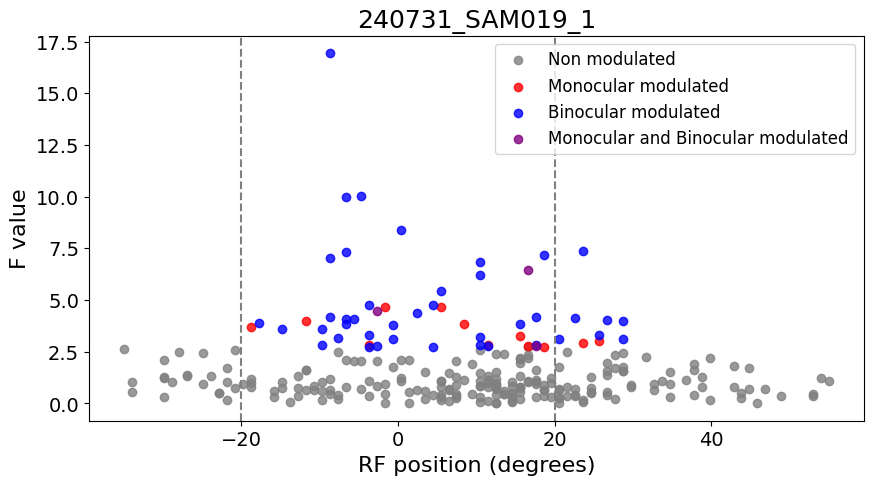

In [254]:
plot_RF_vs_modulation(D)

# Show preferred distance of the cells

In [34]:
preferred_distance = []
for cell in range(len(type)):
    
    amplitude = []
    
    if type[cell] == 'binocular':
        block = 'two eye'
    elif type[cell] == 'monocular':
        block = 'one eye'
    elif type[cell] == 'both':
        block = None
    else:
        preferred_distance.append(None)
        continue
        
    for d in range(1, 5):
        _, a = D.compute_receptive_field(cell=cell, distance=d, block=block, return_amplitude=True)
        amplitude.append(a)
        
    preferred_distance.append(np.argmax(amplitude) + 1)

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_25080\3489194032.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f'{int(i)}' for i in ax.get_yticks()], fontsize=12)


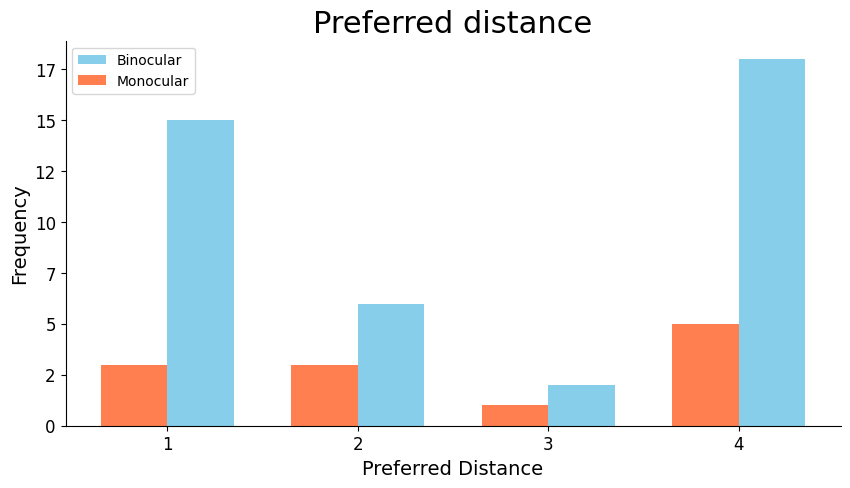

In [282]:
# Example data
categories = [1, 2, 3, 4]

pop_distance_monocular = []
pop_distance_binocular = []

for cell in range(D.dFF.shape[0]):
    
    type = D.stats['type'][cell]
    
    if type == 'un-reliable':
        continue
    elif type == 'un-modulated':
        continue
    elif type == 'monocular':
        pop_distance_monocular.append(D.stats['preferred_distance'][cell])
    elif type == 'binocular':
        pop_distance_binocular.append(D.stats['preferred_distance'][cell])
   
# do bar plot with the two types for each category
# Calculate counts
counts_distance_monocular = [pop_distance_monocular.count(cat) for cat in categories]
counts_distance_binocular = [pop_distance_binocular.count(cat) for cat in categories]

# same with pctg
total_counts_monocular = sum(counts_distance_monocular)
total_counts_binocular = sum(counts_distance_binocular)

percentages_monocular = [i / total_counts_monocular * 100 for i in counts_distance_monocular]
percentages_binocular = [i / total_counts_binocular * 100 for i in counts_distance_binocular]

# Do barplot
x = np.arange(len(categories))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x + width/2, counts_distance_binocular, width, label='Binocular', color='skyblue')
rects2 = ax.bar(x - width/2, counts_distance_monocular, width, label='Monocular', color='coral')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Preferred Distance', fontsize=14)
ax.set_ylabel('Frequency', fontsize=14)
ax.set_title('Preferred distance', fontsize=22)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=12)
ax.set_yticklabels([f'{int(i)}' for i in ax.get_yticks()], fontsize=12)
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

# remove top and right spines

# remove spines



# Exploratory: how one-eye vs two-eye affects response

In [68]:

from scipy.ndimage import gaussian_filter1d

reliable_cells = np.where(np.array(D.stats['type']) != 'un-reliable')[0]
ratio = []
receptive_field = []
type = []

for cell in reliable_cells:

    # get the mean response of the cell to one eye and two eye block
    one_eye = D.get_all_traces(cell, block='one eye', mean_trace=True)[0]
    two_eye = D.get_all_traces(cell, block='two eye', mean_trace=True)[0]
    
    is_one_eye_reliable = D.stats['is_reliable_one_eye'][cell]
    is_two_eye_reliable = D.stats['is_reliable_two_eye'][cell]
    
    if is_two_eye_reliable and is_one_eye_reliable:
        receptive_field_two = D.compute_receptive_field(cell, block='two eye')
        receptive_field_one = D.compute_receptive_field(cell, block='one eye')
    elif is_two_eye_reliable and not is_one_eye_reliable:
        receptive_field_two = D.compute_receptive_field(cell, block='two eye')
        receptive_field_one = receptive_field_two
    elif is_one_eye_reliable and not is_two_eye_reliable:
        receptive_field_one = D.compute_receptive_field(cell, block='one eye')
        receptive_field_two = receptive_field_one
    else:
        print('Cell is not reliable in any block')
        
    # the max value after rolling a 1d gaussian filter of sigma 3
    one_eye_max = gaussian_filter1d(one_eye, 3)[receptive_field_one]
    two_eye_max = np.max(gaussian_filter1d(two_eye, 3)[receptive_field_two])
    
    ratio.append((two_eye_max-one_eye_max) / (one_eye_max + two_eye_max))
    receptive_field.append(D.angle_range[receptive_field_two])
    type.append(D.stats['type'][cell])

In [78]:
# order ratio from highest to lowest
ratio = np.array(ratio)
receptive_field = np.array(receptive_field)
type = np.array(type)

idx = np.argsort(ratio)[::-1]
ratio = ratio[idx]
receptive_field = receptive_field[idx]
type = type[idx]
reliable_cells = reliable_cells[idx]

Cell 164
Ratio: 0.9520107528688905
Receptive Field: -26.86868686868687
Type: un-modulated


In [81]:
cell = -1
print('Cell ' + str(reliable_cells[cell]))
print('Ratio: ' + str(ratio[cell]))
print('Receptive Field: ' + str(receptive_field[cell]))
print('Type: ' + str(type[cell]))

Cell 161
Ratio: -0.9077016778661049
Receptive Field: 19.5959595959596
Type: un-modulated


(array([1., 2., 1., 2., 0., 1., 1., 2., 1., 1.]),
 array([-0.51364252, -0.40561503, -0.29758755, -0.18956006, -0.08153258,
         0.0264949 ,  0.13452239,  0.24254987,  0.35057736,  0.45860484,
         0.56663233]),
 <BarContainer object of 10 artists>)

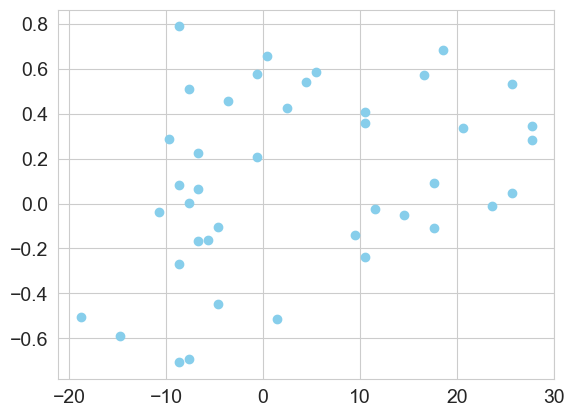

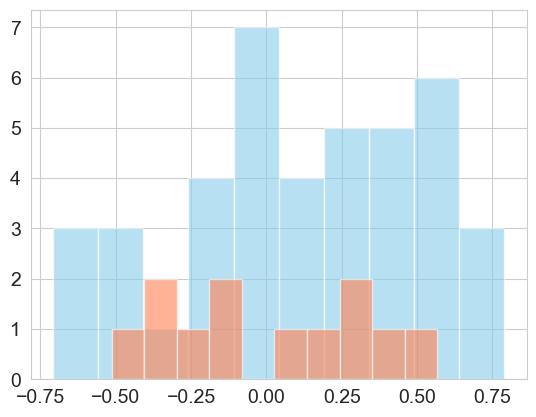

In [76]:
plt.figure()

# scatter receptive field vas ratio and color by type
colors = {'un-modulated': 'gray', 'binocular': 'skyblue', 'monocular': 'coral', 'both': 'plum'}
for t in ['binocular']:
    idx = np.where(np.array(type) == t)
    plt.scatter(np.array(receptive_field)[idx], np.array(ratio)[idx], c=colors[t], label=t)

# do a histogram of the ratio of the binocular
binocular_ratio = np.array(ratio)[np.where(np.array(type) == 'binocular')]
monocular_ratio = np.array(ratio)[np.where(np.array(type) == 'monocular')]


C:\Users\acostamendoza\projects\Distance-Coding-Analysis\src\DistancePlots.py:76: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(['-40', '-20', '0', '20', '40', '60'])


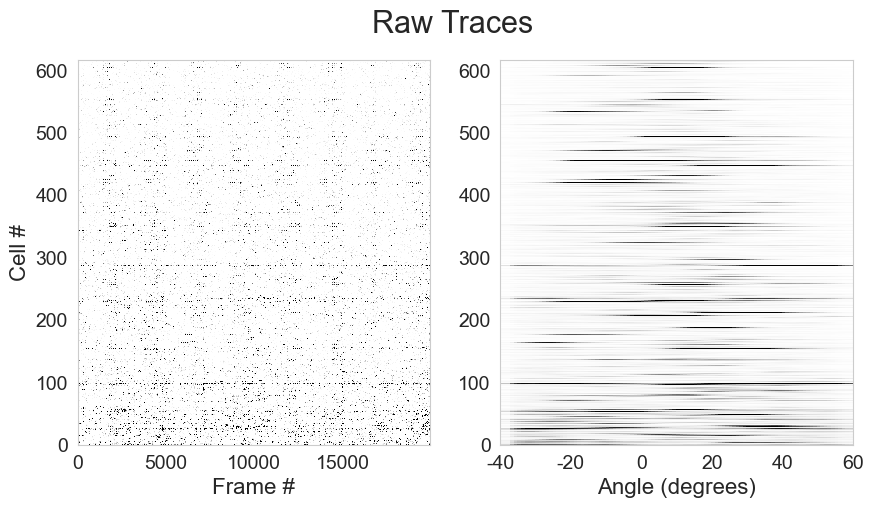

In [82]:
plot_raw_traces(D)

160


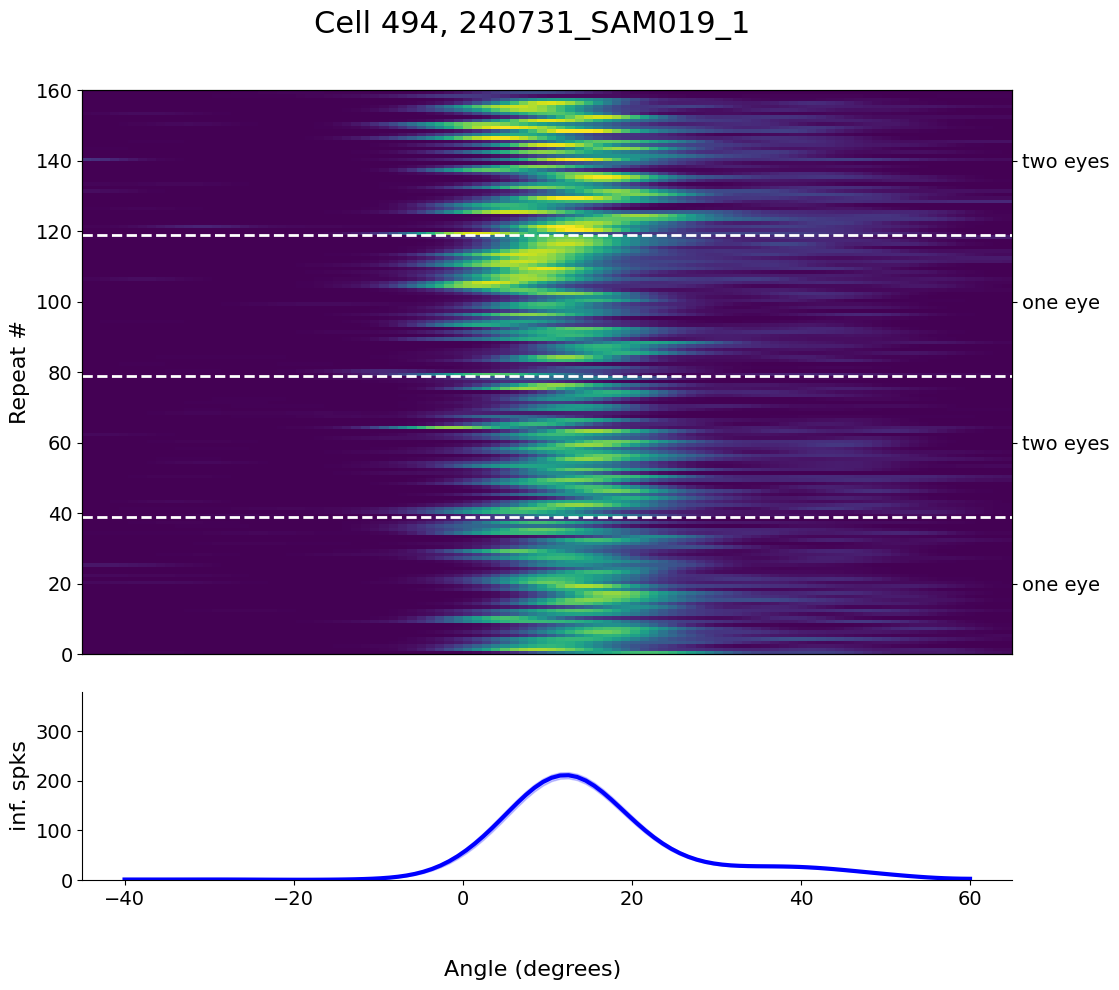

In [8]:
plt.rcParams['image.cmap'] = 'viridis'
plot_trials(D, cell=494, title=imaging_filename)
# set parameters to the usual

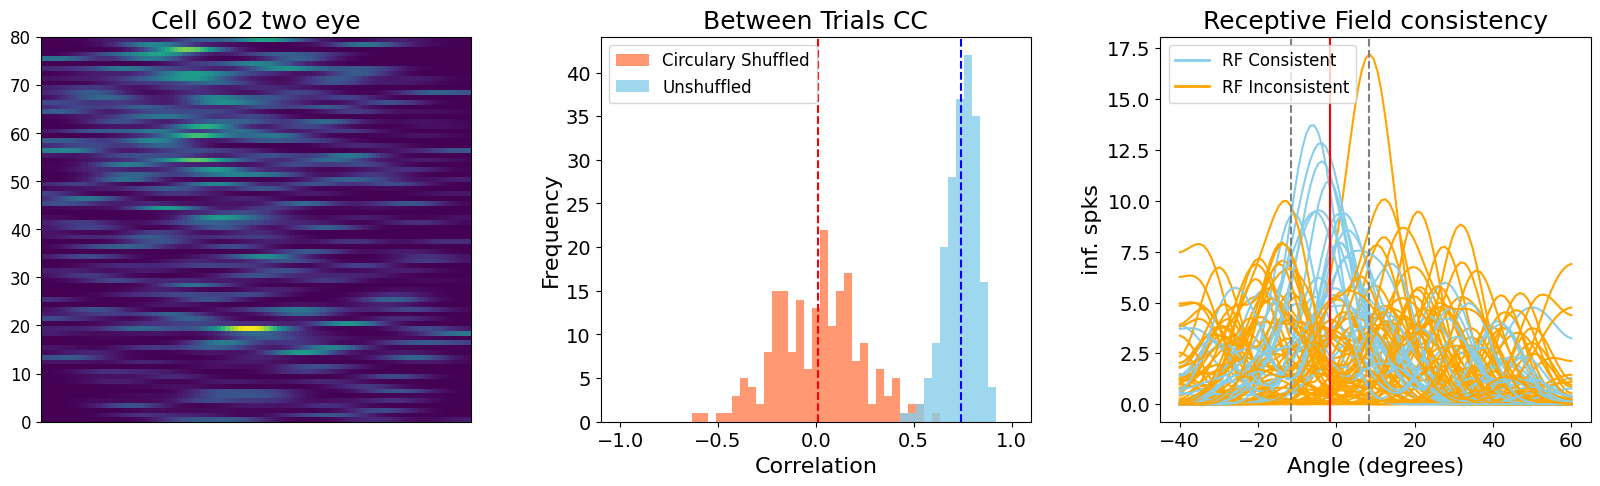

In [23]:
plot_cell_reliability(D, cell = 602, block='two eye')

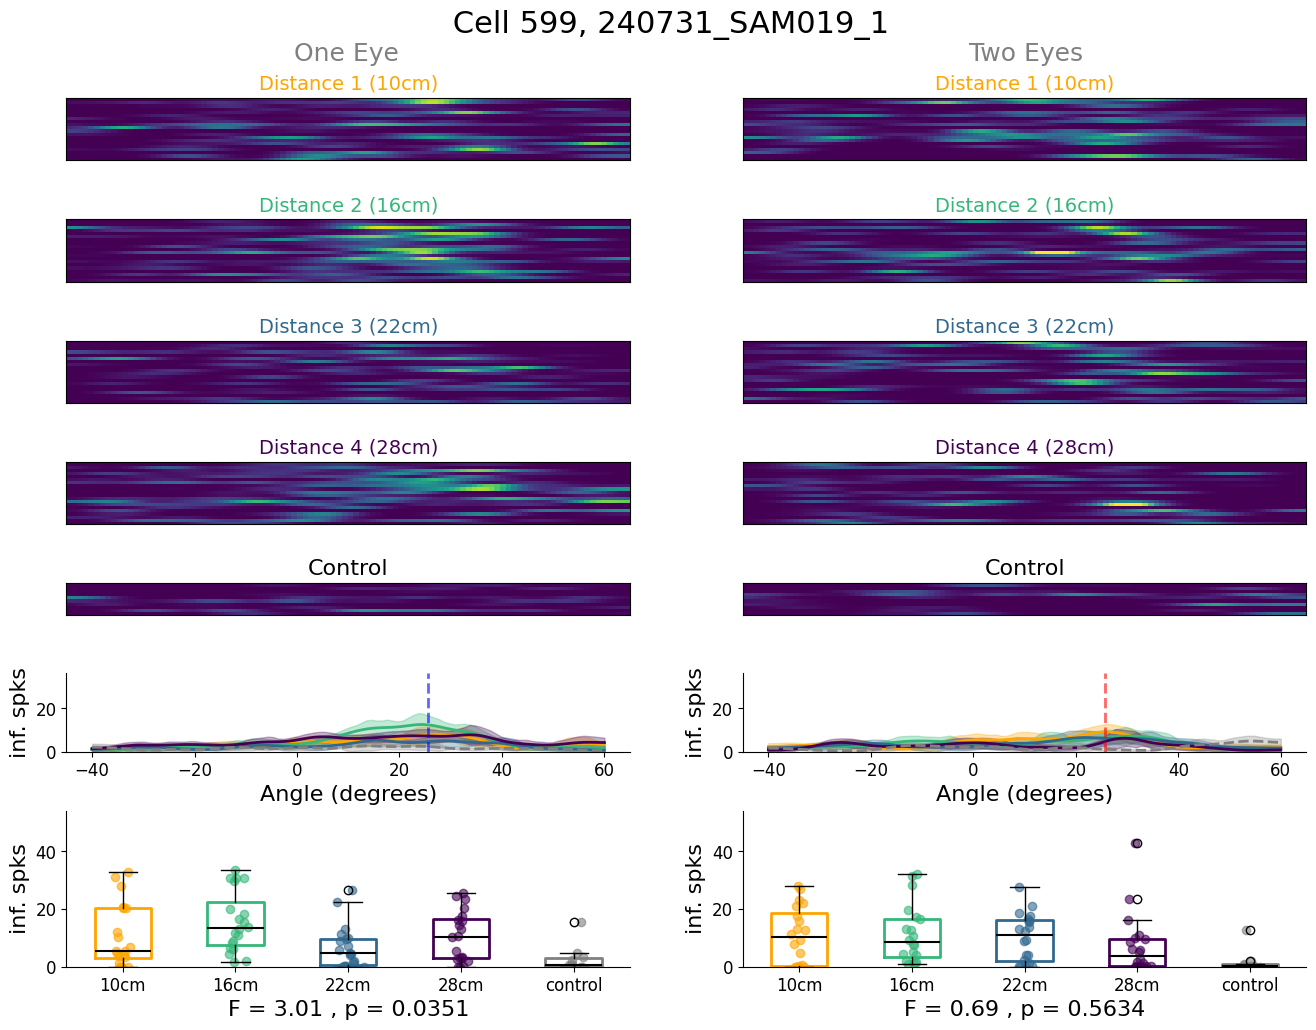

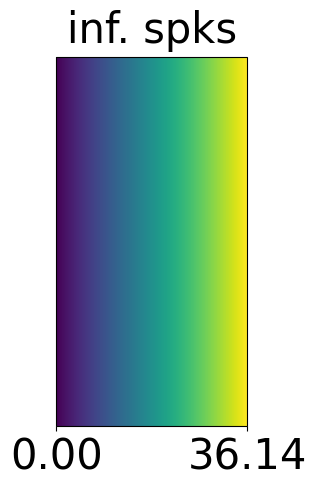

In [62]:
plot_trials_ordered_2(D, cell=599, title=imaging_filename)
plt.show()

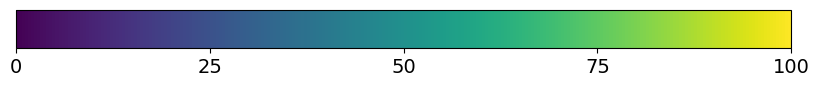

In [32]:
import matplotlib as mpl
# Define the limits and colormap
vmin = 0
vmax = 100
cmap = 'viridis'
norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)

# Create a ScalarMappable and set the colormap
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Create a figure and axis for the colorbar
fig, ax = plt.subplots(figsize=(10, 4))  # Adjust the figsize to make it long and thin

# Create the colorbar
cbar = fig.colorbar(sm, cax=ax, orientation='horizontal', ticks=np.linspace(vmin, vmax, 500))

# set only 5 ticks
cbar.set_ticks(np.linspace(vmin, vmax, 5))

# Set the aspect ratio
cbar.ax.set_aspect(5)  # Adjust the aspect ratio as needed

plt.show()

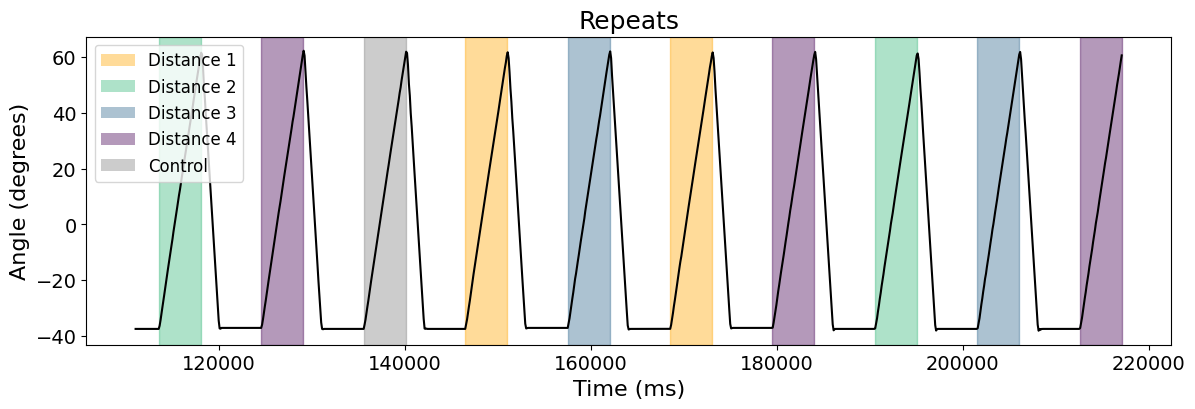

In [253]:
plot_repeats(D, np.arange(10,20))

In [72]:
reliability_one_eye = D.stats['reliability_one_eye']
reliability_two_eye = D.stats['reliability_two_eye']

# sort these two from higher to lower
idx = np.argsort(reliability_two_eye)[::-1]
print(idx)

directory = create_new_result_dir(imaging_dir, 'reliability')

for i in idx[:50]:
    
    plot_trials_ordered_2(D, cell=i, title=imaging_filename)
    plt.savefig(directory + '/' + str(i) + '.png')
    plt.close()
    
idx = np.argsort(reliability_two_eye)[::-1]

for i in idx[:100]:
    
    plot_trials_ordered_2(D, cell=i, title=imaging_filename)
    plt.savefig(directory + '/' + str(i) + '.png')
    plt.close()
    
idx = np.argsort(reliability_two_eye)[::-1]

for i in idx[:100]:
    
    plot_trials_ordered_2(D, cell=i, title=imaging_filename)
    plt.savefig(directory + '/' + str(i) + '.png')
    plt.close()
    

[243 238 365 374 175 307 251 304 250 341 289 271 347 285 290 107 252 361
  70 118 158 168 376 189 146 188  58 321  26 351  84 233  85 370  88 214
 174  62  96   9 283  25 196 295 190  66 334 183 320 363  40  61  74 367
 131 180  65 371 108 373 140 343 270  10  80 305  79  86 195 106  72 135
 139 316 349  99 310 227   2 109  55 302  42  39  37  91 102 301 237  89
  49 221 230  11 229  52 136 112 357 157 200 333  93 141 154  16  27   8
 113   4 309 206 297 311  21  17  50 101  95  33 284 193  64 224  76 247
 170 348 152 163 372  15 219  34 259  30  41 222  63 274 364  59 359 337
 228  71 124 208 288 209 253 220  75  98  51 191 111  32 207 277 181 132
 119 340  97  23 330   0  83 143 164 331 244 280 262  38   3 338 204 336
  22 194  87 314 150  19 294 255   5 327  56 122 282 160 130 225 246 328
 126 293 169 356 123  20 308 105  12 198 133  24  90 125  29 324 177 291
 358 197 258 145  48 151 137 362   7 326 298  69  67 312 276 352  43 115
 281 149 350 249  77 184 292  53  31 345  47 103 27